# 🏥 AI-Powered ER Wait Time Prediction System

## Project Overview
This notebook implements a machine learning pipeline to predict Emergency Room waiting times and detect high-risk long waits for intelligent hospital resource scheduling.

### Objectives:
1. **Regression**: Predict patient waiting time (minutes)
2. **Classification**: Detect high-risk long waits (>60 minutes)
3. **Deployment**: Prepare models for cloud-native integration

### Dataset:
ER Wait Time Dataset from Kaggle

### Environment:
- CPU-only training
- Time-aware validation splits
- Production-ready code for FastAPI deployment

## 📦 Import Libraries

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime, timedelta
import joblib
import json

# Sklearn preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Metrics
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Visualization settings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("✅ All libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

✅ All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 1.26.4


In [2]:
# Setup directory for saving figures
import os

FIGURES_DIR = 'figures'
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_figure(filename, fig=None, dpi=300, bbox_inches='tight'):
    """
    Save matplotlib figure to the figures directory
    
    Args:
        filename (str): Name of the file (e.g., 'wait_time_distribution.png')
        fig: Matplotlib figure object (if None, uses current figure)
        dpi (int): Resolution for saving
        bbox_inches (str): Bounding box setting
    """
    filepath = os.path.join(FIGURES_DIR, filename)
    if fig is None:
        plt.savefig(filepath, dpi=dpi, bbox_inches=bbox_inches)
    else:
        fig.savefig(filepath, dpi=dpi, bbox_inches=bbox_inches)
    print(f"📊 Figure saved: {filepath}")

print(f"✅ Figures directory created: {FIGURES_DIR}/")
print("💡 Use save_figure('filename.png') after creating plots to save them")

✅ Figures directory created: figures/
💡 Use save_figure('filename.png') after creating plots to save them


## 📊 Load Dataset

**Note**: When running on Kaggle, update the path to `/kaggle/input/er-wait-time-dataset/` or the appropriate Kaggle dataset path.

For local testing, we'll create a synthetic dataset that mimics realistic ER data.

In [3]:
# Dataset loading configuration
# On Kaggle, use: DATA_PATH = '/kaggle/input/er-wait-time-dataset/'
# For local development, we'll generate synthetic data

import os

# Check if running on Kaggle
IS_KAGGLE = os.path.exists('/kaggle/input')

if IS_KAGGLE:
    # Update this path to match your Kaggle dataset
    DATA_PATH = '/kaggle/input/er-wait-time'
    df_raw = pd.read_csv(os.path.join(DATA_PATH, 'ER Wait Time Dataset.csv'))
    print("✅ Loaded data from Kaggle")
    
    # Map Kaggle columns to expected schema
    df = pd.DataFrame({
        'patient_id': df_raw['Patient ID'],
        'arrival_time': pd.to_datetime(df_raw['Visit Date']),
        'triage_level': df_raw['Urgency Level'].map({'Low': 5, 'Medium': 3, 'High': 1}).fillna(3).astype(int),
        'age': np.random.normal(45, 20, len(df_raw)).clip(0, 100).astype(int),  # Age not in dataset, using synthetic
        'department': df_raw['Hospital Name'].apply(lambda x: 'General' if 'General' in str(x) else 
                                                               'Cardiac' if 'Cardiac' in str(x) else
                                                               'Pediatric' if 'Pediatric' in str(x) else 'General'),
        'num_doctors_available': df_raw['Specialist Availability'],
        'queue_length': (df_raw['Nurse-to-Patient Ratio'] * 10).fillna(15).astype(int),  # Approximate queue from ratio
        'is_weekend': df_raw['Day of Week'].isin(['Saturday', 'Sunday']).astype(int),
        'wait_time': df_raw['Total Wait Time (min)']
    })
    
    print("✅ Kaggle columns mapped to expected schema")
    
elif os.path.exists('ER Wait Time Dataset.csv'):
    # Local CSV file exists
    df_raw = pd.read_csv('ER Wait Time Dataset.csv')
    print("✅ Loaded local CSV file")
    
    # Map columns to expected schema
    df = pd.DataFrame({
        'patient_id': df_raw['Patient ID'],
        'arrival_time': pd.to_datetime(df_raw['Visit Date']),
        'triage_level': df_raw['Urgency Level'].map({'Low': 5, 'Medium': 3, 'High': 1}).fillna(3).astype(int),
        'age': np.random.normal(45, 20, len(df_raw)).clip(0, 100).astype(int),  # Age not in dataset, using synthetic
        'department': df_raw['Hospital Name'].apply(lambda x: 'General' if 'General' in str(x) else 
                                                               'Cardiac' if 'Cardiac' in str(x) else
                                                               'Pediatric' if 'Pediatric' in str(x) else 'General'),
        'num_doctors_available': df_raw['Specialist Availability'],
        'queue_length': (df_raw['Nurse-to-Patient Ratio'] * 10).fillna(15).astype(int),  # Approximate queue from ratio
        'is_weekend': df_raw['Day of Week'].isin(['Saturday', 'Sunday']).astype(int),
        'wait_time': df_raw['Total Wait Time (min)']
    })
    
    print("✅ Local CSV columns mapped to expected schema")
    
else:
    print("🔧 Generating synthetic ER dataset for development...")
    
    # Generate realistic synthetic data
    np.random.seed(42)
    n_samples = 5000
    
    # Generate timestamps over 90 days
    start_date = pd.Timestamp('2024-01-01')
    timestamps = [start_date + timedelta(minutes=np.random.randint(0, 90*24*60)) 
                  for _ in range(n_samples)]
    
    df = pd.DataFrame({
        'patient_id': range(1, n_samples + 1),
        'arrival_time': timestamps,
        'triage_level': np.random.choice([1, 2, 3, 4, 5], n_samples, p=[0.05, 0.15, 0.35, 0.30, 0.15]),
        'age': np.random.normal(45, 20, n_samples).clip(0, 100).astype(int),
        'department': np.random.choice(['General', 'Trauma', 'Pediatric', 'Cardiac'], n_samples),
        'num_doctors_available': np.random.randint(2, 12, n_samples),
        'queue_length': np.random.randint(0, 50, n_samples),
        'is_weekend': np.random.choice([0, 1], n_samples, p=[5/7, 2/7]),
    })
    
    # Generate realistic wait times based on features
    base_wait = 30
    wait_time = (
        base_wait +
        (6 - df['triage_level']) * 15 +  # Higher urgency = shorter wait
        df['queue_length'] * 2 +           # More queue = longer wait
        np.random.normal(0, 10, n_samples) -  # Random variation
        df['num_doctors_available'] * 3 +  # More doctors = shorter wait
        df['is_weekend'] * 10               # Weekends may be busier
    ).clip(5, 300)  # Reasonable bounds
    
    df['wait_time'] = wait_time.astype(int)
    
    # Add some missing values to make it realistic
    missing_idx = np.random.choice(df.index, size=int(0.02*n_samples), replace=False)
    df.loc[missing_idx, 'num_doctors_available'] = np.nan
    
    print("✅ Synthetic dataset generated")

print(f"\n📏 Dataset shape: {df.shape}")
print(f"📅 Date range: {df['arrival_time'].min()} to {df['arrival_time'].max()}")
print("\n👁️ First few rows:")
df.head()


✅ Loaded data from Kaggle
✅ Kaggle columns mapped to expected schema

📏 Dataset shape: (5000, 9)
📅 Date range: 2024-01-01 05:08:49 to 2024-12-30 23:14:07

👁️ First few rows:


,patient_id,arrival_time,triage_level,age,department,num_doctors_available,queue_length,is_weekend,wait_time
0,PAT-00001,2024-02-10 20:20:56,3,32,General,3,40,1,105
1,PAT-00002,2024-11-28 02:07:47,3,48,General,0,40,0,69
2,PAT-00003,2024-09-30 04:02:28,5,39,General,1,50,0,203
3,PAT-00004,2024-02-27 00:31:13,1,67,General,5,40,0,88
4,PAT-00005,2024-03-06 16:52:26,5,37,General,8,40,0,118


## 🔍 Exploratory Data Analysis (EDA)

In [4]:
# Dataset overview
print("="*60)
print("📊 DATASET OVERVIEW")
print("="*60)
print(f"\nShape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")
print("\n" + "="*60)
print("📋 DATA TYPES")
print("="*60)
print(df.dtypes)
print("\n" + "="*60)
print("📈 SUMMARY STATISTICS")
print("="*60)
df.describe()

📊 DATASET OVERVIEW

Shape: 5000 rows × 9 columns

Columns: ['patient_id', 'arrival_time', 'triage_level', 'age', 'department', 'num_doctors_available', 'queue_length', 'is_weekend', 'wait_time']

📋 DATA TYPES
patient_id                       object
arrival_time             datetime64[ns]
triage_level                      int64
age                               int64
department                       object
num_doctors_available             int64
queue_length                      int64
is_weekend                        int64
wait_time                         int64
dtype: object

📈 SUMMARY STATISTICS


,arrival_time,triage_level,age,num_doctors_available,queue_length,is_weekend,wait_time
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2024-06-30 11:59:40.381599744,2.990800,43.895800,3.875000,32.382000,0.285200,81.916600
min,2024-01-01 05:08:49,1.000000,0.000000,0.000000,10.000000,0.000000,4.000000
25%,2024-03-31 08:05:54.750000128,3.000000,30.000000,1.000000,30.000000,0.000000,27.000000
50%,2024-06-30 10:34:09.500000,3.000000,44.000000,3.000000,30.000000,0.000000,60.000000
75%,2024-09-29 05:34:02.750000128,3.000000,57.000000,6.000000,40.000000,1.000000,122.000000
max,2024-12-30 23:14:07,5.000000,100.000000,10.000000,50.000000,1.000000,442.000000
std,NaN,1.404959,19.703192,3.043292,12.008952,0.451555,68.084538


In [5]:
# Check for missing values
print("="*60)
print("❓ MISSING VALUES")
print("="*60)
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Percentage': missing_pct
})
missing_df[missing_df['Missing Count'] > 0]

❓ MISSING VALUES


,Missing Count,Percentage


📊 Figure saved: figures/01_wait_time_distribution.png


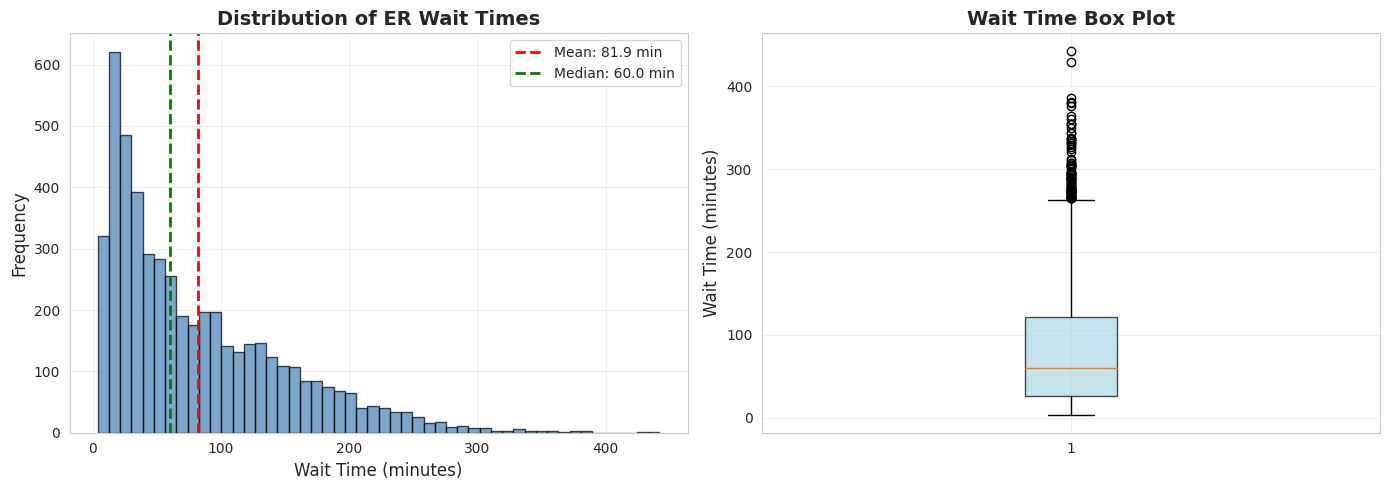

Wait Time Statistics:
  Mean: 81.92 minutes
  Median: 60.00 minutes
  Std: 68.08 minutes
  Min: 4.00 minutes
  Max: 442.00 minutes


In [6]:
# Visualize target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wait time distribution
axes[0].hist(df['wait_time'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(df['wait_time'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["wait_time"].mean():.1f} min')
axes[0].axvline(df['wait_time'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df["wait_time"].median():.1f} min')
axes[0].set_xlabel('Wait Time (minutes)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Distribution of ER Wait Times', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Box plot
axes[1].boxplot(df['wait_time'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', alpha=0.7))
axes[1].set_ylabel('Wait Time (minutes)', fontsize=12)
axes[1].set_title('Wait Time Box Plot', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_figure('01_wait_time_distribution.png')
plt.show()

print(f"Wait Time Statistics:")
print(f"  Mean: {df['wait_time'].mean():.2f} minutes")
print(f"  Median: {df['wait_time'].median():.2f} minutes")
print(f"  Std: {df['wait_time'].std():.2f} minutes")
print(f"  Min: {df['wait_time'].min():.2f} minutes")
print(f"  Max: {df['wait_time'].max():.2f} minutes")

📊 Figure saved: figures/02_categorical_features_analysis.png


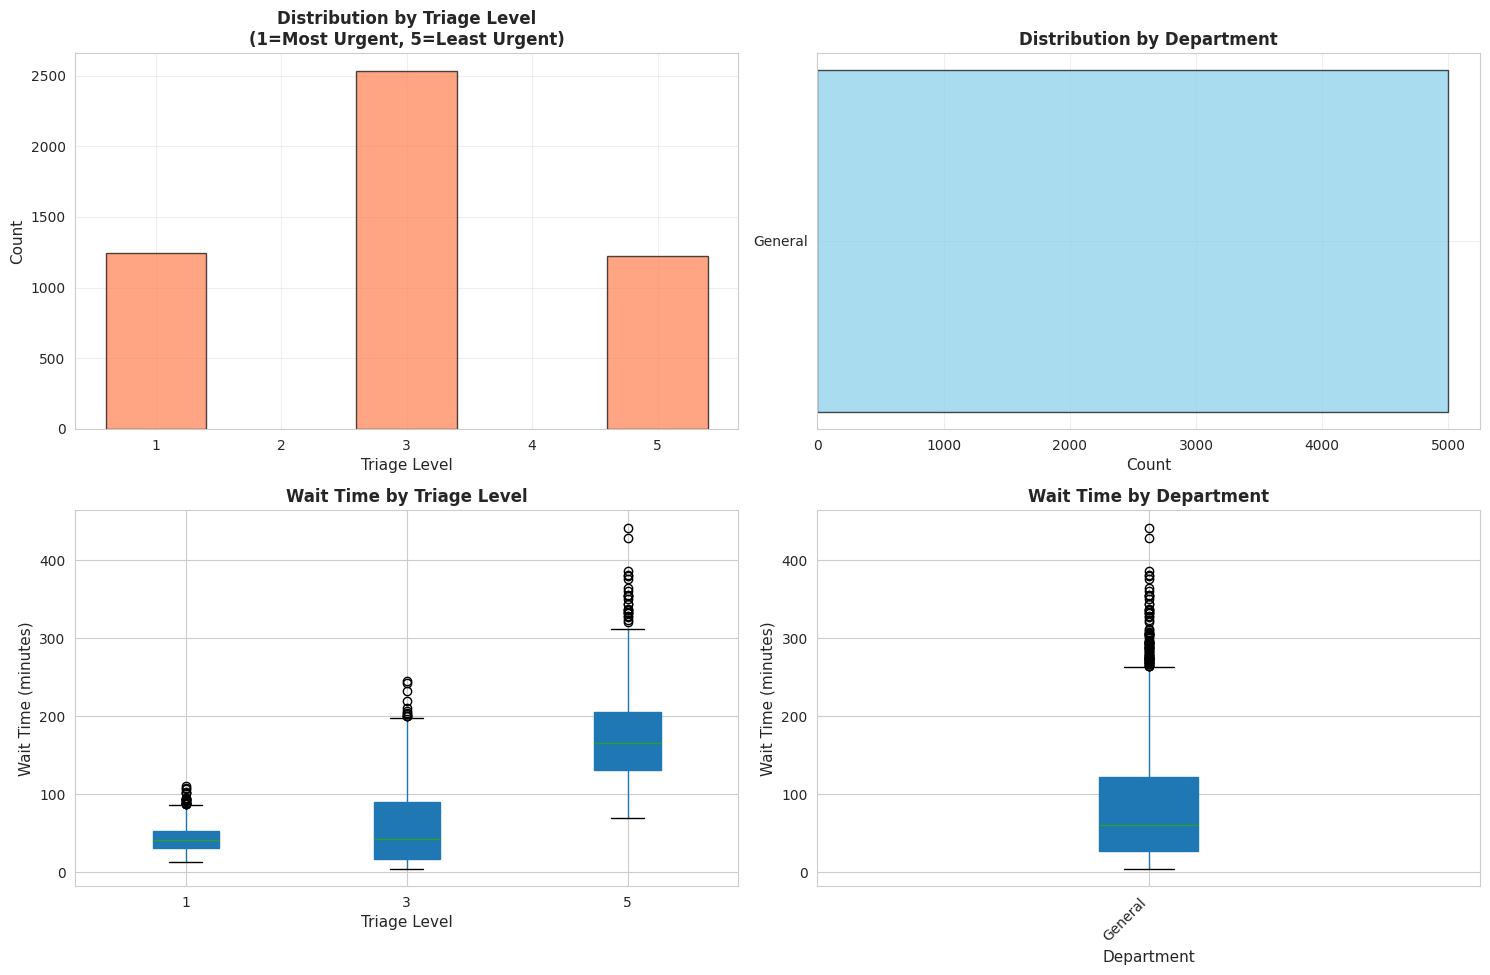

In [7]:
# Analyze categorical features
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Triage level distribution
triage_counts = df['triage_level'].value_counts().sort_index()
axes[0, 0].bar(triage_counts.index, triage_counts.values, color='coral', alpha=0.7, edgecolor='black')
axes[0, 0].set_xlabel('Triage Level', fontsize=11)
axes[0, 0].set_ylabel('Count', fontsize=11)
axes[0, 0].set_title('Distribution by Triage Level\n(1=Most Urgent, 5=Least Urgent)', fontsize=12, fontweight='bold')
axes[0, 0].grid(alpha=0.3)

# Department distribution
dept_counts = df['department'].value_counts()
axes[0, 1].barh(dept_counts.index, dept_counts.values, color='skyblue', alpha=0.7, edgecolor='black')
axes[0, 1].set_xlabel('Count', fontsize=11)
axes[0, 1].set_title('Distribution by Department', fontsize=12, fontweight='bold')
axes[0, 1].grid(alpha=0.3)

# Wait time by triage level
df.boxplot(column='wait_time', by='triage_level', ax=axes[1, 0], patch_artist=True)
axes[1, 0].set_xlabel('Triage Level', fontsize=11)
axes[1, 0].set_ylabel('Wait Time (minutes)', fontsize=11)
axes[1, 0].set_title('Wait Time by Triage Level', fontsize=12, fontweight='bold')
axes[1, 0].get_figure().suptitle('')  # Remove default title
plt.setp(axes[1, 0].xaxis.get_majorticklabels(), rotation=0)

# Wait time by department
df.boxplot(column='wait_time', by='department', ax=axes[1, 1], patch_artist=True)
axes[1, 1].set_xlabel('Department', fontsize=11)
axes[1, 1].set_ylabel('Wait Time (minutes)', fontsize=11)
axes[1, 1].set_title('Wait Time by Department', fontsize=12, fontweight='bold')
axes[1, 1].get_figure().suptitle('')  # Remove default title
plt.setp(axes[1, 1].xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
save_figure('02_categorical_features_analysis.png')
plt.show()

📊 Figure saved: figures/03_correlation_heatmap.png


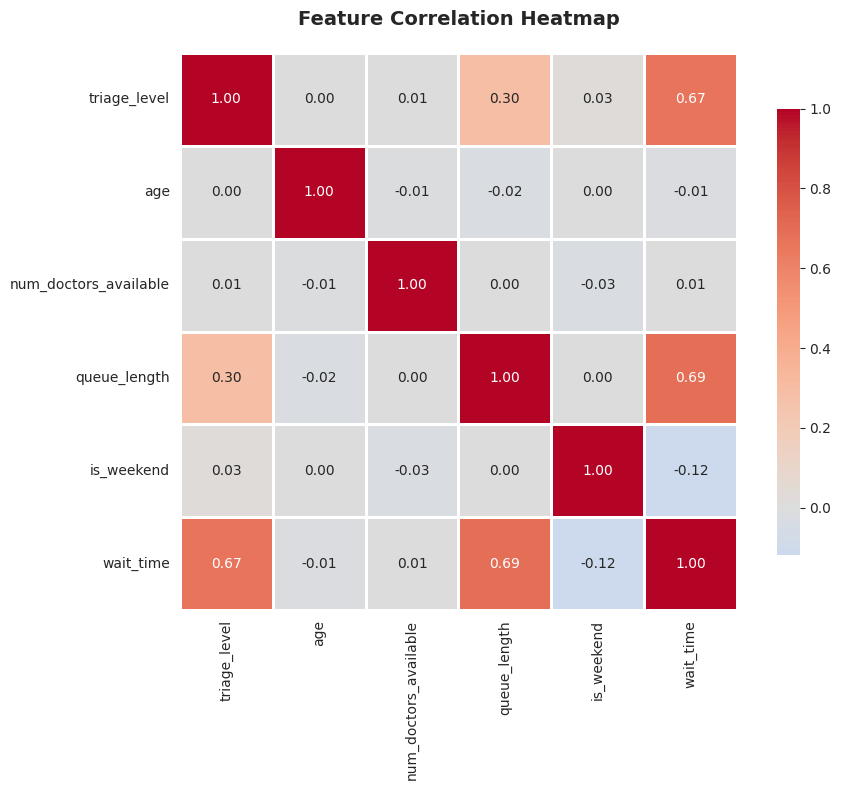


Top correlations with wait_time:
wait_time                1.000000
queue_length             0.688015
triage_level             0.669943
num_doctors_available    0.006579
age                     -0.014182
is_weekend              -0.117075
Name: wait_time, dtype: float64


In [8]:
# Correlation analysis for numerical features
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'patient_id' in numerical_cols:
    numerical_cols.remove('patient_id')

correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
save_figure('03_correlation_heatmap.png')
plt.show()

print("\nTop correlations with wait_time:")
wait_time_corr = correlation_matrix['wait_time'].sort_values(ascending=False)
print(wait_time_corr)

## 🔧 Feature Engineering

Key features to extract:
- **Temporal**: Hour of day, day of week, is_weekend
- **Operational**: Queue length, available doctors, triage urgency
- **Categorical**: Department encoding
- **Target for Classification**: Long wait indicator (>60 min)

In [9]:
# Handle missing values
print("="*60)
print("🔧 HANDLING MISSING VALUES")
print("="*60)

# Create a copy for feature engineering
df_fe = df.copy()

# Impute numerical features with median
numerical_features = ['num_doctors_available', 'queue_length', 'age']
for col in numerical_features:
    if df_fe[col].isnull().sum() > 0:
        median_val = df_fe[col].median()
        df_fe[col].fillna(median_val, inplace=True)
        print(f"✅ Filled {col} with median: {median_val}")

# Check remaining missing values
remaining_missing = df_fe.isnull().sum().sum()
print(f"\n✅ Remaining missing values: {remaining_missing}")

# Handle outliers (cap extreme values)
print("\n" + "="*60)
print("🔧 HANDLING OUTLIERS")
print("="*60)

def cap_outliers(series, lower_percentile=1, upper_percentile=99):
    lower = series.quantile(lower_percentile/100)
    upper = series.quantile(upper_percentile/100)
    return series.clip(lower, upper)

df_fe['queue_length'] = cap_outliers(df_fe['queue_length'])
df_fe['wait_time'] = cap_outliers(df_fe['wait_time'], 0.5, 99.5)

print("✅ Outliers capped for queue_length and wait_time")
print(f"   Wait time range: {df_fe['wait_time'].min():.0f} - {df_fe['wait_time'].max():.0f} minutes")

🔧 HANDLING MISSING VALUES

✅ Remaining missing values: 0

🔧 HANDLING OUTLIERS
✅ Outliers capped for queue_length and wait_time
   Wait time range: 6 - 311 minutes


In [10]:
# Convert arrival_time to datetime if not already
df_fe['arrival_time'] = pd.to_datetime(df_fe['arrival_time'])

# Extract temporal features
df_fe['arrival_hour'] = df_fe['arrival_time'].dt.hour
df_fe['arrival_day_of_week'] = df_fe['arrival_time'].dt.dayofweek  # 0=Monday, 6=Sunday
df_fe['arrival_month'] = df_fe['arrival_time'].dt.month
df_fe['arrival_day'] = df_fe['arrival_time'].dt.day

# Create time-of-day categories
def categorize_time_of_day(hour):
    if 6 <= hour < 12:
        return 'morning'
    elif 12 <= hour < 18:
        return 'afternoon'
    elif 18 <= hour < 24:
        return 'evening'
    else:
        return 'night'

df_fe['time_of_day'] = df_fe['arrival_hour'].apply(categorize_time_of_day)

# Weekend flag (if not already present)
if 'is_weekend' not in df_fe.columns:
    df_fe['is_weekend'] = (df_fe['arrival_day_of_week'] >= 5).astype(int)

# Rush hour indicator (peak times: 9-11 AM, 6-8 PM)
df_fe['is_rush_hour'] = ((df_fe['arrival_hour'].between(9, 11)) | 
                          (df_fe['arrival_hour'].between(18, 20))).astype(int)

# Doctor-to-patient ratio
df_fe['doctor_patient_ratio'] = df_fe['num_doctors_available'] / (df_fe['queue_length'] + 1)

# Create binary target for classification: long wait (>60 minutes)
df_fe['long_wait'] = (df_fe['wait_time'] > 60).astype(int)

print("✅ Temporal features created")
print(f"   - arrival_hour: {df_fe['arrival_hour'].min()}-{df_fe['arrival_hour'].max()}")
print(f"   - arrival_day_of_week: {df_fe['arrival_day_of_week'].min()}-{df_fe['arrival_day_of_week'].max()}")
print(f"   - time_of_day: {df_fe['time_of_day'].unique()}")
print(f"   - is_rush_hour: {df_fe['is_rush_hour'].sum()} rush hour arrivals")
print(f"\n✅ Operational features created")
print(f"   - doctor_patient_ratio: mean = {df_fe['doctor_patient_ratio'].mean():.2f}")
print(f"\n✅ Classification target created")
print(f"   - long_wait distribution:\n{df_fe['long_wait'].value_counts()}")
print(f"   - Long wait percentage: {df_fe['long_wait'].mean()*100:.1f}%")

✅ Temporal features created
   - arrival_hour: 0-23
   - arrival_day_of_week: 0-6
   - time_of_day: ['evening' 'night' 'afternoon' 'morning']
   - is_rush_hour: 1301 rush hour arrivals

✅ Operational features created
   - doctor_patient_ratio: mean = 0.14

✅ Classification target created
   - long_wait distribution:
long_wait
0    2507
1    2493
Name: count, dtype: int64
   - Long wait percentage: 49.9%


In [11]:
# Encode categorical variables
print("="*60)
print("🔧 ENCODING CATEGORICAL VARIABLES")
print("="*60)

# One-hot encode department
df_encoded = pd.get_dummies(df_fe, columns=['department', 'time_of_day'], prefix=['dept', 'tod'], drop_first=False)

# Label encode if needed (for tree-based models, one-hot is often better)
print(f"✅ One-hot encoded: department, time_of_day")
print(f"   New shape: {df_encoded.shape}")
print(f"   New columns added: {df_encoded.shape[1] - df_fe.shape[1]}")

# Display final feature set
print("\n" + "="*60)
print("📋 FINAL FEATURE SET")
print("="*60)
print(df_encoded.columns.tolist())

🔧 ENCODING CATEGORICAL VARIABLES
✅ One-hot encoded: department, time_of_day
   New shape: (5000, 20)
   New columns added: 3

📋 FINAL FEATURE SET
['patient_id', 'arrival_time', 'triage_level', 'age', 'num_doctors_available', 'queue_length', 'is_weekend', 'wait_time', 'arrival_hour', 'arrival_day_of_week', 'arrival_month', 'arrival_day', 'is_rush_hour', 'doctor_patient_ratio', 'long_wait', 'dept_General', 'tod_afternoon', 'tod_evening', 'tod_morning', 'tod_night']


## 🔀 Train-Test Split (Time-Aware)

**Critical**: Use time-based splitting to prevent data leakage. We'll split chronologically.

In [12]:
# Sort by arrival time for temporal split
df_encoded = df_encoded.sort_values('arrival_time').reset_index(drop=True)

# Define features to exclude from modeling
exclude_cols = ['patient_id', 'arrival_time', 'wait_time', 'long_wait']

# Get feature columns
feature_cols = [col for col in df_encoded.columns if col not in exclude_cols]

print(f"Total features for modeling: {len(feature_cols)}")
print(f"\nFeatures: {feature_cols}")

# Prepare data for regression (wait_time prediction)
X = df_encoded[feature_cols].copy()
y_regression = df_encoded['wait_time'].copy()
y_classification = df_encoded['long_wait'].copy()

# Time-based split (80% train, 20% test)
split_idx = int(0.8 * len(df_encoded))

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_reg_train = y_regression.iloc[:split_idx]
y_reg_test = y_regression.iloc[split_idx:]

y_clf_train = y_classification.iloc[:split_idx]
y_clf_test = y_classification.iloc[split_idx:]

print("\n" + "="*60)
print("📊 DATASET SPLIT")
print("="*60)
print(f"Training set: {len(X_train)} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set:     {len(X_test)} samples ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nRegression target (wait_time):")
print(f"  Train mean: {y_reg_train.mean():.2f} minutes")
print(f"  Test mean:  {y_reg_test.mean():.2f} minutes")
print(f"\nClassification target (long_wait):")
print(f"  Train positives: {y_clf_train.sum()} ({y_clf_train.mean()*100:.1f}%)")
print(f"  Test positives:  {y_clf_test.sum()} ({y_clf_test.mean()*100:.1f}%)")

Total features for modeling: 16

Features: ['triage_level', 'age', 'num_doctors_available', 'queue_length', 'is_weekend', 'arrival_hour', 'arrival_day_of_week', 'arrival_month', 'arrival_day', 'is_rush_hour', 'doctor_patient_ratio', 'dept_General', 'tod_afternoon', 'tod_evening', 'tod_morning', 'tod_night']

📊 DATASET SPLIT
Training set: 4000 samples (80.0%)
Test set:     1000 samples (20.0%)

Regression target (wait_time):
  Train mean: 81.96 minutes
  Test mean:  80.69 minutes

Classification target (long_wait):
  Train positives: 1994 (49.9%)
  Test positives:  499 (49.9%)


In [13]:
# Feature scaling for models that need it
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Feature scaling completed")
print(f"   Scaler fitted on {X_train.shape[0]} training samples")
print(f"   Feature means: {scaler.mean_[:5]} ...")
print(f"   Feature stds:  {scaler.scale_[:5]} ...")

✅ Feature scaling completed
   Scaler fitted on 4000 training samples
   Feature means: [ 2.9985 43.7085  3.8505 32.3125  0.2845] ...
   Feature stds:  [ 1.40534613 19.72784904  3.03177337 12.05517913  0.45117596] ...


## 🤖 Regression Models: Wait Time Prediction

We'll train and compare three regression models:
1. **Linear Regression** (baseline)
2. **Random Forest Regressor**
3. **XGBoost Regressor** (expected best performer)

### 1️⃣ Linear Regression (Baseline)

In [14]:
print("="*60)
print("🔵 LINEAR REGRESSION")
print("="*60)

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_reg_train)

# Predictions
y_pred_lr_train = lr_model.predict(X_train_scaled)
y_pred_lr_test = lr_model.predict(X_test_scaled)

# Evaluate
lr_train_mae = mean_absolute_error(y_reg_train, y_pred_lr_train)
lr_train_rmse = np.sqrt(mean_squared_error(y_reg_train, y_pred_lr_train))
lr_train_r2 = r2_score(y_reg_train, y_pred_lr_train)

lr_test_mae = mean_absolute_error(y_reg_test, y_pred_lr_test)
lr_test_rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_lr_test))
lr_test_r2 = r2_score(y_reg_test, y_pred_lr_test)

print(f"\n📊 Training Performance:")
print(f"   MAE:  {lr_train_mae:.2f} minutes")
print(f"   RMSE: {lr_train_rmse:.2f} minutes")
print(f"   R²:   {lr_train_r2:.4f}")

print(f"\n📊 Test Performance:")
print(f"   MAE:  {lr_test_mae:.2f} minutes")
print(f"   RMSE: {lr_test_rmse:.2f} minutes")
print(f"   R²:   {lr_test_r2:.4f}")

print("\n✅ Linear Regression training complete")

🔵 LINEAR REGRESSION

📊 Training Performance:
   MAE:  24.33 minutes
   RMSE: 33.10 minutes
   R²:   0.7590

📊 Test Performance:
   MAE:  28.27 minutes
   RMSE: 38.91 minutes
   R²:   0.6582

✅ Linear Regression training complete


### 2️⃣ Random Forest Regressor

In [15]:
print("="*60)
print("🌳 RANDOM FOREST REGRESSOR")
print("="*60)

# Train Random Forest (optimized for CPU)
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,  # Use all CPU cores
    verbose=0
)

print("Training Random Forest...")
rf_model.fit(X_train, y_reg_train)

# Predictions
y_pred_rf_train = rf_model.predict(X_train)
y_pred_rf_test = rf_model.predict(X_test)

# Evaluate
rf_train_mae = mean_absolute_error(y_reg_train, y_pred_rf_train)
rf_train_rmse = np.sqrt(mean_squared_error(y_reg_train, y_pred_rf_train))
rf_train_r2 = r2_score(y_reg_train, y_pred_rf_train)

rf_test_mae = mean_absolute_error(y_reg_test, y_pred_rf_test)
rf_test_rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_rf_test))
rf_test_r2 = r2_score(y_reg_test, y_pred_rf_test)

print(f"\n📊 Training Performance:")
print(f"   MAE:  {rf_train_mae:.2f} minutes")
print(f"   RMSE: {rf_train_rmse:.2f} minutes")
print(f"   R²:   {rf_train_r2:.4f}")

print(f"\n📊 Test Performance:")
print(f"   MAE:  {rf_test_mae:.2f} minutes")
print(f"   RMSE: {rf_test_rmse:.2f} minutes")
print(f"   R²:   {rf_test_r2:.4f}")

print("\n✅ Random Forest training complete")

🌳 RANDOM FOREST REGRESSOR
Training Random Forest...

📊 Training Performance:
   MAE:  12.05 minutes
   RMSE: 18.02 minutes
   R²:   0.9286

📊 Test Performance:
   MAE:  22.65 minutes
   RMSE: 35.03 minutes
   R²:   0.7230

✅ Random Forest training complete


### 3️⃣ XGBoost Regressor (Main Model)

In [16]:
print("="*60)
print("🚀 XGBOOST REGRESSOR")
print("="*60)

# Train XGBoost (optimized for CPU)
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',  # Faster on CPU
    verbosity=0
)

print("Training XGBoost...")
xgb_model.fit(X_train, y_reg_train)

# Predictions
y_pred_xgb_train = xgb_model.predict(X_train)
y_pred_xgb_test = xgb_model.predict(X_test)

# Evaluate
xgb_train_mae = mean_absolute_error(y_reg_train, y_pred_xgb_train)
xgb_train_rmse = np.sqrt(mean_squared_error(y_reg_train, y_pred_xgb_train))
xgb_train_r2 = r2_score(y_reg_train, y_pred_xgb_train)

xgb_test_mae = mean_absolute_error(y_reg_test, y_pred_xgb_test)
xgb_test_rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_xgb_test))
xgb_test_r2 = r2_score(y_reg_test, y_pred_xgb_test)

print(f"\n📊 Training Performance:")
print(f"   MAE:  {xgb_train_mae:.2f} minutes")
print(f"   RMSE: {xgb_train_rmse:.2f} minutes")
print(f"   R²:   {xgb_train_r2:.4f}")

print(f"\n📊 Test Performance:")
print(f"   MAE:  {xgb_test_mae:.2f} minutes")
print(f"   RMSE: {xgb_test_rmse:.2f} minutes")
print(f"   R²:   {xgb_test_r2:.4f}")

print("\n✅ XGBoost training complete")

🚀 XGBOOST REGRESSOR
Training XGBoost...

📊 Training Performance:
   MAE:  8.26 minutes
   RMSE: 11.79 minutes
   R²:   0.9694

📊 Test Performance:
   MAE:  23.28 minutes
   RMSE: 35.57 minutes
   R²:   0.7145

✅ XGBoost training complete


### 📊 Regression Models Comparison

🏆 REGRESSION MODELS COMPARISON
            Model  Train MAE  Test MAE  Train RMSE  Test RMSE  Train R²  Test R²
Linear Regression  24.332926 28.270612   33.097065  38.914289  0.758990 0.658235
    Random Forest  12.048353 22.647789   18.016779  35.032165  0.928582 0.723023
          XGBoost   8.259670 23.279178   11.788576  35.569929  0.969424 0.714454

🥇 Best Model: Random Forest (Lowest Test MAE)
📊 Figure saved: figures/04_regression_models_comparison.png


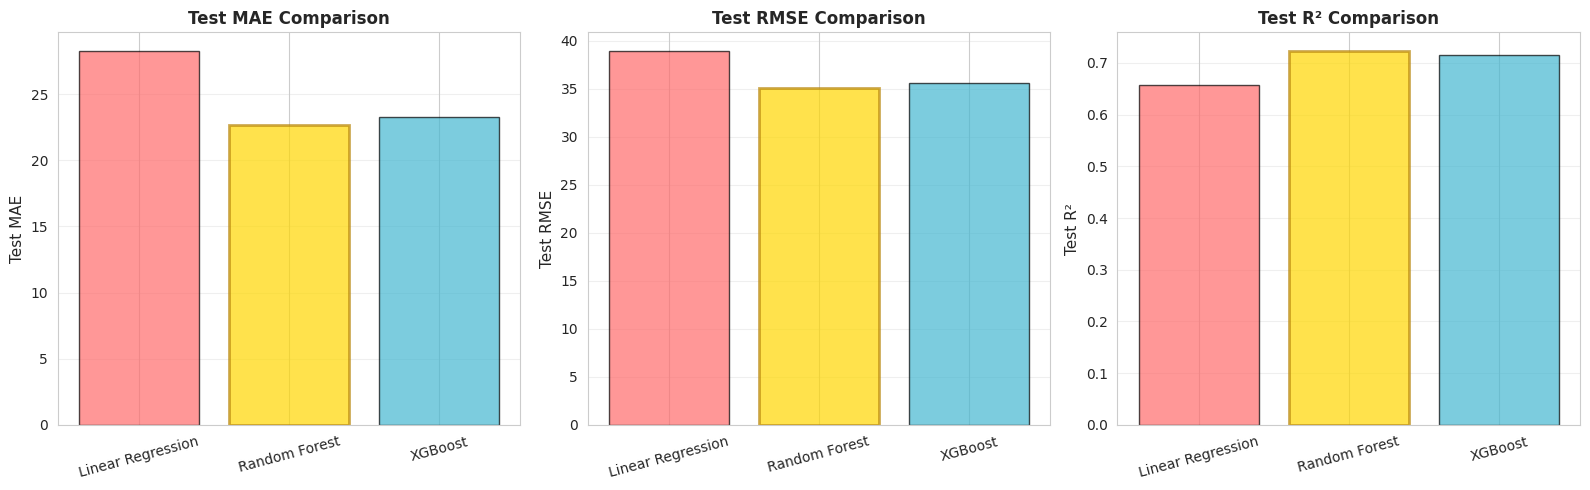

In [17]:
# Comparison table
regression_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'Train MAE': [lr_train_mae, rf_train_mae, xgb_train_mae],
    'Test MAE': [lr_test_mae, rf_test_mae, xgb_test_mae],
    'Train RMSE': [lr_train_rmse, rf_train_rmse, xgb_train_rmse],
    'Test RMSE': [lr_test_rmse, rf_test_rmse, xgb_test_rmse],
    'Train R²': [lr_train_r2, rf_train_r2, xgb_train_r2],
    'Test R²': [lr_test_r2, rf_test_r2, xgb_test_r2]
})

print("="*80)
print("🏆 REGRESSION MODELS COMPARISON")
print("="*80)
print(regression_results.to_string(index=False))

# Identify best model
best_idx = regression_results['Test MAE'].idxmin()
best_model_name = regression_results.loc[best_idx, 'Model']
print(f"\n🥇 Best Model: {best_model_name} (Lowest Test MAE)")

# Visualize comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['Test MAE', 'Test RMSE', 'Test R²']
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

for idx, metric in enumerate(metrics):
    axes[idx].bar(regression_results['Model'], regression_results[metric], 
                  color=colors, alpha=0.7, edgecolor='black')
    axes[idx].set_ylabel(metric, fontsize=11)
    axes[idx].set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    axes[idx].tick_params(axis='x', rotation=15)
    axes[idx].grid(alpha=0.3, axis='y')
    
    # Highlight best
    best_val_idx = regression_results[metric].idxmin() if 'R²' not in metric else regression_results[metric].idxmax()
    axes[idx].patches[best_val_idx].set_facecolor('gold')
    axes[idx].patches[best_val_idx].set_edgecolor('darkgoldenrod')
    axes[idx].patches[best_val_idx].set_linewidth(2)

plt.tight_layout()
save_figure('04_regression_models_comparison.png')
plt.show()

### 🎯 Feature Importance Analysis

📊 Figure saved: figures/05_feature_importance.png


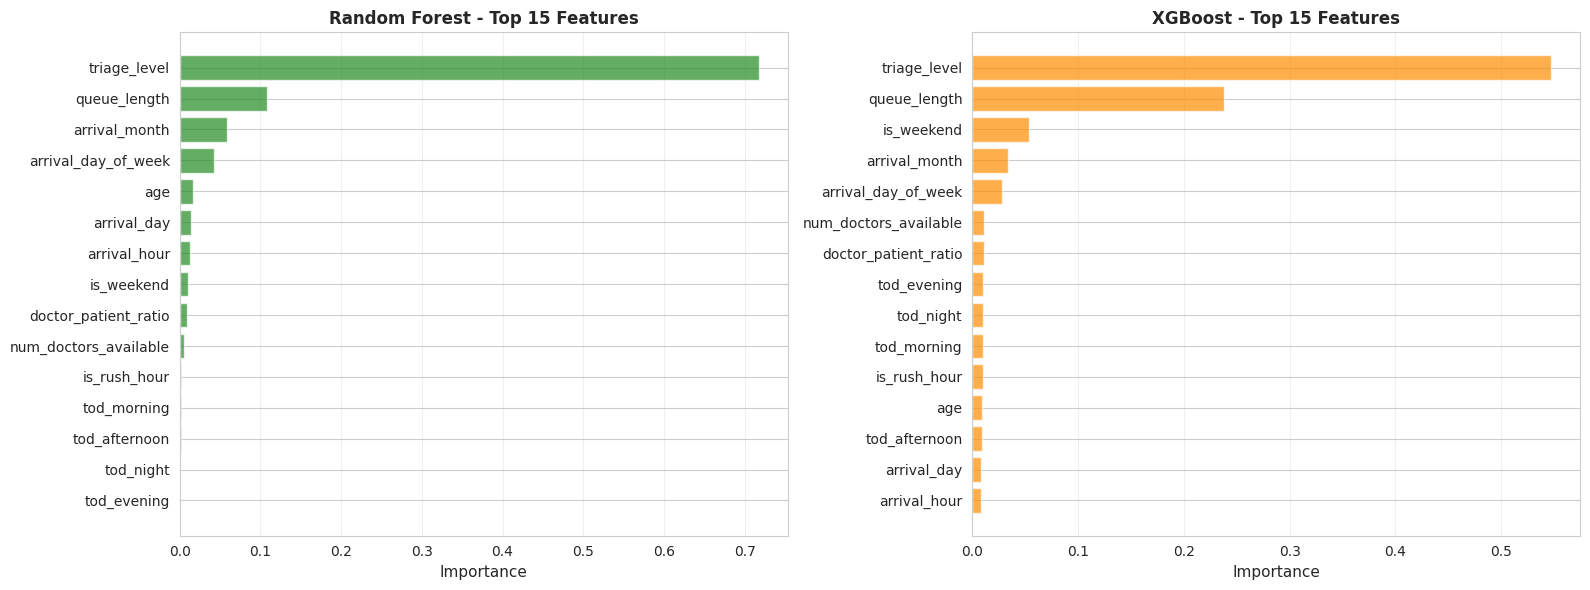

🔝 Top 5 Most Important Features (XGBoost):
   triage_level: 0.5471
   queue_length: 0.2379
   is_weekend: 0.0541
   arrival_month: 0.0338
   arrival_day_of_week: 0.0280


In [18]:
# Feature importance from tree-based models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random Forest feature importance
rf_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

axes[0].barh(rf_importance['Feature'], rf_importance['Importance'], color='forestgreen', alpha=0.7)
axes[0].set_xlabel('Importance', fontsize=11)
axes[0].set_title('Random Forest - Top 15 Features', fontsize=12, fontweight='bold')
axes[0].invert_yaxis()
axes[0].grid(alpha=0.3, axis='x')

# XGBoost feature importance
xgb_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

axes[1].barh(xgb_importance['Feature'], xgb_importance['Importance'], color='darkorange', alpha=0.7)
axes[1].set_xlabel('Importance', fontsize=11)
axes[1].set_title('XGBoost - Top 15 Features', fontsize=12, fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
save_figure('05_feature_importance.png')
plt.show()

print("🔝 Top 5 Most Important Features (XGBoost):")
for idx, row in xgb_importance.head(5).iterrows():
    print(f"   {row['Feature']}: {row['Importance']:.4f}")

### 📈 Error Analysis

📊 Figure saved: figures/06_error_analysis.png


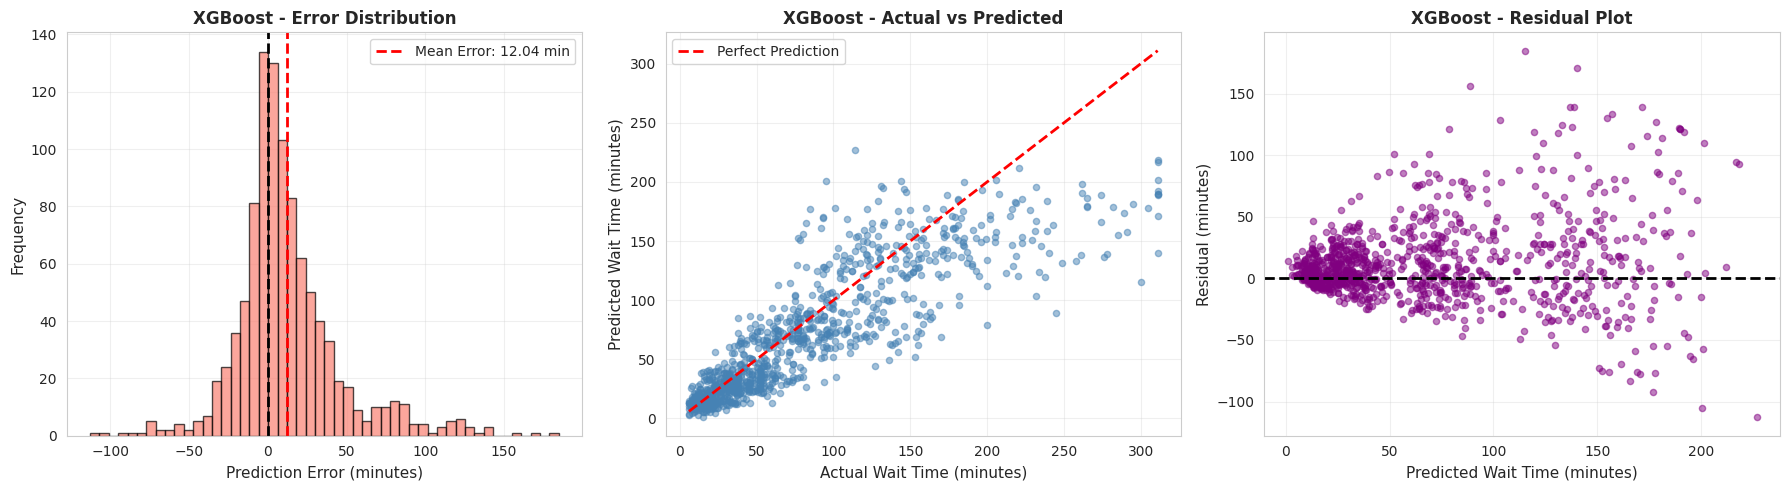

Error Statistics (XGBoost):
  Mean Error: 12.04 minutes
  Std Error:  33.49 minutes
  Median Absolute Error: 14.25 minutes


In [19]:
# Error distribution for XGBoost (best model)
errors = y_reg_test - y_pred_xgb_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Error distribution
axes[0].hist(errors, bins=50, edgecolor='black', alpha=0.7, color='salmon')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].axvline(errors.mean(), color='red', linestyle='--', linewidth=2, 
                label=f'Mean Error: {errors.mean():.2f} min')
axes[0].set_xlabel('Prediction Error (minutes)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('XGBoost - Error Distribution', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Actual vs Predicted
axes[1].scatter(y_reg_test, y_pred_xgb_test, alpha=0.5, s=20, color='steelblue')
axes[1].plot([y_reg_test.min(), y_reg_test.max()], 
             [y_reg_test.min(), y_reg_test.max()], 
             'r--', linewidth=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Wait Time (minutes)', fontsize=11)
axes[1].set_ylabel('Predicted Wait Time (minutes)', fontsize=11)
axes[1].set_title('XGBoost - Actual vs Predicted', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Residuals plot
axes[2].scatter(y_pred_xgb_test, errors, alpha=0.5, s=20, color='purple')
axes[2].axhline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Predicted Wait Time (minutes)', fontsize=11)
axes[2].set_ylabel('Residual (minutes)', fontsize=11)
axes[2].set_title('XGBoost - Residual Plot', fontsize=12, fontweight='bold')
axes[2].grid(alpha=0.3)

plt.tight_layout()
save_figure('06_error_analysis.png')
plt.show()

print(f"Error Statistics (XGBoost):")
print(f"  Mean Error: {errors.mean():.2f} minutes")
print(f"  Std Error:  {errors.std():.2f} minutes")
print(f"  Median Absolute Error: {np.median(np.abs(errors)):.2f} minutes")

## 🎯 Classification Models: Long-Wait Detection

Binary classification task: Predict if wait time will exceed 60 minutes

Models:
1. **Logistic Regression** (baseline)
2. **XGBoost Classifier** (main model)

### 1️⃣ Logistic Regression (Baseline)

In [20]:
print("="*60)
print("🔵 LOGISTIC REGRESSION CLASSIFIER")
print("="*60)

# Train Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
log_reg.fit(X_train_scaled, y_clf_train)

# Predictions
y_pred_log_train = log_reg.predict(X_train_scaled)
y_pred_log_test = log_reg.predict(X_test_scaled)
y_pred_log_test_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# Evaluate
log_train_acc = accuracy_score(y_clf_train, y_pred_log_train)
log_test_acc = accuracy_score(y_clf_test, y_pred_log_test)
log_test_precision = precision_score(y_clf_test, y_pred_log_test)
log_test_recall = recall_score(y_clf_test, y_pred_log_test)
log_test_f1 = f1_score(y_clf_test, y_pred_log_test)
log_test_auc = roc_auc_score(y_clf_test, y_pred_log_test_proba)

print(f"\n📊 Training Accuracy: {log_train_acc:.4f}")
print(f"\n📊 Test Performance:")
print(f"   Accuracy:  {log_test_acc:.4f}")
print(f"   Precision: {log_test_precision:.4f}")
print(f"   Recall:    {log_test_recall:.4f}")
print(f"   F1-Score:  {log_test_f1:.4f}")
print(f"   ROC-AUC:   {log_test_auc:.4f}")

print("\n✅ Logistic Regression training complete")

🔵 LOGISTIC REGRESSION CLASSIFIER

📊 Training Accuracy: 0.9165

📊 Test Performance:
   Accuracy:  0.8720
   Precision: 0.9344
   Recall:    0.7996
   F1-Score:  0.8618
   ROC-AUC:   0.9629

✅ Logistic Regression training complete


### 2️⃣ XGBoost Classifier

In [21]:
print("="*60)
print("🚀 XGBOOST CLASSIFIER")
print("="*60)

# Train XGBoost Classifier
xgb_clf = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
    verbosity=0,
    scale_pos_weight=len(y_clf_train[y_clf_train==0]) / len(y_clf_train[y_clf_train==1])  # Handle class imbalance
)

print("Training XGBoost Classifier...")
xgb_clf.fit(X_train, y_clf_train)

# Predictions
y_pred_xgb_clf_train = xgb_clf.predict(X_train)
y_pred_xgb_clf_test = xgb_clf.predict(X_test)
y_pred_xgb_clf_test_proba = xgb_clf.predict_proba(X_test)[:, 1]

# Evaluate
xgb_clf_train_acc = accuracy_score(y_clf_train, y_pred_xgb_clf_train)
xgb_clf_test_acc = accuracy_score(y_clf_test, y_pred_xgb_clf_test)
xgb_clf_test_precision = precision_score(y_clf_test, y_pred_xgb_clf_test)
xgb_clf_test_recall = recall_score(y_clf_test, y_pred_xgb_clf_test)
xgb_clf_test_f1 = f1_score(y_clf_test, y_pred_xgb_clf_test)
xgb_clf_test_auc = roc_auc_score(y_clf_test, y_pred_xgb_clf_test_proba)

print(f"\n📊 Training Accuracy: {xgb_clf_train_acc:.4f}")
print(f"\n📊 Test Performance:")
print(f"   Accuracy:  {xgb_clf_test_acc:.4f}")
print(f"   Precision: {xgb_clf_test_precision:.4f}")
print(f"   Recall:    {xgb_clf_test_recall:.4f}")
print(f"   F1-Score:  {xgb_clf_test_f1:.4f}")
print(f"   ROC-AUC:   {xgb_clf_test_auc:.4f}")

print("\n✅ XGBoost Classifier training complete")

🚀 XGBOOST CLASSIFIER
Training XGBoost Classifier...

📊 Training Accuracy: 0.9938

📊 Test Performance:
   Accuracy:  0.8830
   Precision: 0.9341
   Recall:    0.8236
   F1-Score:  0.8754
   ROC-AUC:   0.9680

✅ XGBoost Classifier training complete


### 📊 Classification Models Comparison

🏆 CLASSIFICATION MODELS COMPARISON
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression     0.872   0.934426 0.799599  0.861771 0.962880
            XGBoost     0.883   0.934091 0.823647  0.875399 0.968004

🥇 Best Model: XGBoost (Highest F1-Score)
📊 Figure saved: figures/07_classification_models_comparison.png


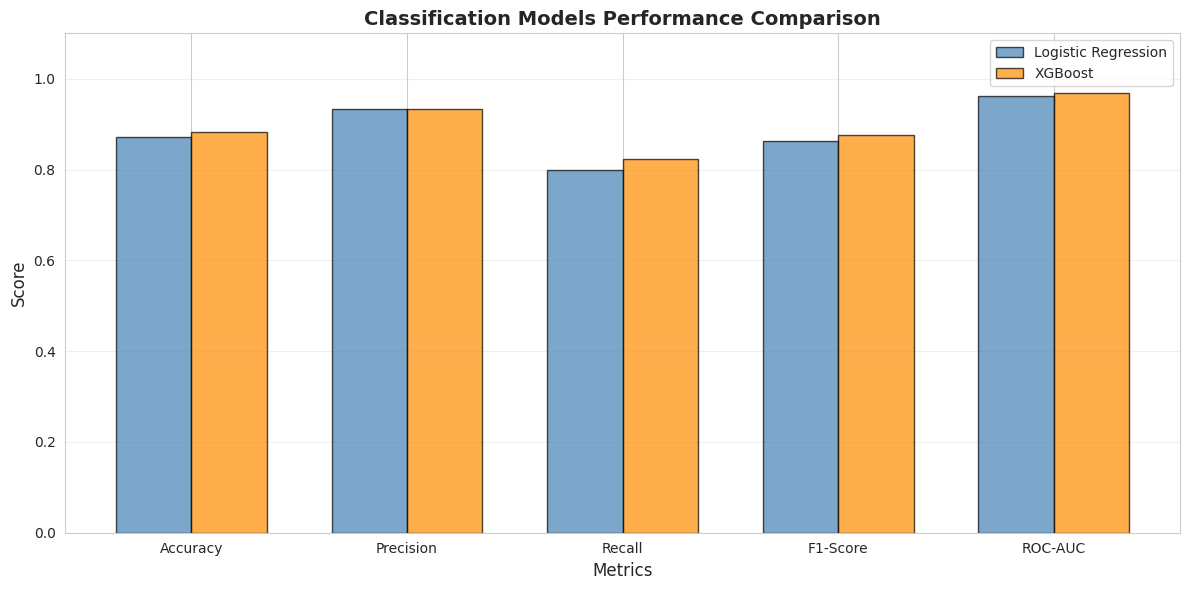

In [22]:
# Comparison table
classification_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'XGBoost'],
    'Accuracy': [log_test_acc, xgb_clf_test_acc],
    'Precision': [log_test_precision, xgb_clf_test_precision],
    'Recall': [log_test_recall, xgb_clf_test_recall],
    'F1-Score': [log_test_f1, xgb_clf_test_f1],
    'ROC-AUC': [log_test_auc, xgb_clf_test_auc]
})

print("="*80)
print("🏆 CLASSIFICATION MODELS COMPARISON")
print("="*80)
print(classification_results.to_string(index=False))

# Identify best model
best_clf_idx = classification_results['F1-Score'].idxmax()
best_clf_name = classification_results.loc[best_clf_idx, 'Model']
print(f"\n🥇 Best Model: {best_clf_name} (Highest F1-Score)")

# Visualize comparison
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(metrics))
width = 0.35

bars1 = ax.bar(x - width/2, classification_results.iloc[0][metrics], width, 
               label='Logistic Regression', alpha=0.7, color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, classification_results.iloc[1][metrics], width,
               label='XGBoost', alpha=0.7, color='darkorange', edgecolor='black')

ax.set_ylabel('Score', fontsize=12)
ax.set_xlabel('Metrics', fontsize=12)
ax.set_title('Classification Models Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(alpha=0.3, axis='y')
ax.set_ylim([0, 1.1])

plt.tight_layout()
save_figure('07_classification_models_comparison.png')
plt.show()

### 🎭 Confusion Matrix & ROC Curve

📊 Figure saved: figures/08_confusion_matrix_roc_curve.png


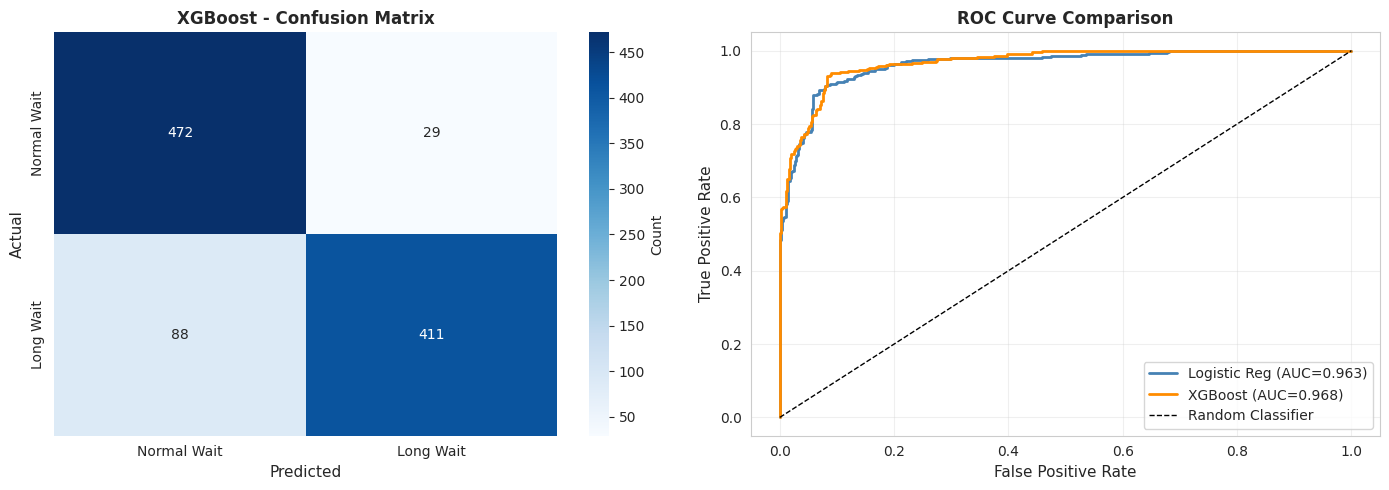


📋 CLASSIFICATION REPORT - XGBoost
                       precision    recall  f1-score   support

Normal Wait (≤60 min)       0.84      0.94      0.89       501
  Long Wait (>60 min)       0.93      0.82      0.88       499

             accuracy                           0.88      1000
            macro avg       0.89      0.88      0.88      1000
         weighted avg       0.89      0.88      0.88      1000



In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix for XGBoost Classifier
cm = confusion_matrix(y_clf_test, y_pred_xgb_clf_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=['Normal Wait', 'Long Wait'],
            yticklabels=['Normal Wait', 'Long Wait'],
            cbar_kws={'label': 'Count'})
axes[0].set_ylabel('Actual', fontsize=11)
axes[0].set_xlabel('Predicted', fontsize=11)
axes[0].set_title('XGBoost - Confusion Matrix', fontsize=12, fontweight='bold')

# ROC Curve
fpr_log, tpr_log, _ = roc_curve(y_clf_test, y_pred_log_test_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_clf_test, y_pred_xgb_clf_test_proba)

axes[1].plot(fpr_log, tpr_log, label=f'Logistic Reg (AUC={log_test_auc:.3f})', 
             linewidth=2, color='steelblue')
axes[1].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC={xgb_clf_test_auc:.3f})', 
             linewidth=2, color='darkorange')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[1].set_xlabel('False Positive Rate', fontsize=11)
axes[1].set_ylabel('True Positive Rate', fontsize=11)
axes[1].set_title('ROC Curve Comparison', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_figure('08_confusion_matrix_roc_curve.png')
plt.show()

# Classification report for best model (XGBoost)
print("\n" + "="*60)
print("📋 CLASSIFICATION REPORT - XGBoost")
print("="*60)
print(classification_report(y_clf_test, y_pred_xgb_clf_test, 
                           target_names=['Normal Wait (≤60 min)', 'Long Wait (>60 min)']))

## 🎲 Uncertainty Estimation with Quantile Regression

Implementing prediction intervals to provide wait-time ranges instead of point estimates.

In [24]:
# Implement quantile regression using XGBoost
from sklearn.base import BaseEstimator, RegressorMixin

class QuantileXGBoostRegressor(BaseEstimator, RegressorMixin):
    """XGBoost with quantile regression objective"""
    def __init__(self, quantile=0.5, **kwargs):
        self.quantile = quantile
        self.kwargs = kwargs
        self.model = None
        
    def fit(self, X, y):
        params = {
            'objective': 'reg:quantileerror',
            'quantile_alpha': self.quantile,
            **self.kwargs
        }
        self.model = XGBRegressor(**params)
        self.model.fit(X, y)
        return self
    
    def predict(self, X):
        return self.model.predict(X)

# Train models for different quantiles
print("="*60)
print("📊 QUANTILE REGRESSION - UNCERTAINTY ESTIMATION")
print("="*60)

quantiles = [0.25, 0.5, 0.75]
quantile_models = {}
quantile_predictions = {}

for q in quantiles:
    print(f"\nTraining {int(q*100)}th percentile model...")
    model = QuantileXGBoostRegressor(
        quantile=q,
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        tree_method='hist',
        verbosity=0
    )
    model.fit(X_train, y_reg_train)
    quantile_models[q] = model
    quantile_predictions[q] = model.predict(X_test)

# Calculate prediction intervals
pred_lower = quantile_predictions[0.25]
pred_median = quantile_predictions[0.5]
pred_upper = quantile_predictions[0.75]

print("\n✅ Quantile regression complete!")
print(f"\nExample predictions with uncertainty:")
for i in range(5):
    print(f"  Patient {i+1}: {pred_lower[i]:.1f} - {pred_median[i]:.1f} - {pred_upper[i]:.1f} minutes (25th-50th-75th percentile)")
    print(f"             Actual: {y_reg_test.iloc[i]:.1f} minutes")

📊 QUANTILE REGRESSION - UNCERTAINTY ESTIMATION

Training 25th percentile model...

Training 50th percentile model...

Training 75th percentile model...

✅ Quantile regression complete!

Example predictions with uncertainty:
  Patient 1: 137.4 - 157.5 - 172.0 minutes (25th-50th-75th percentile)
             Actual: 132.0 minutes
  Patient 2: 72.4 - 87.4 - 110.6 minutes (25th-50th-75th percentile)
             Actual: 132.0 minutes
  Patient 3: 73.0 - 82.3 - 100.9 minutes (25th-50th-75th percentile)
             Actual: 83.0 minutes
  Patient 4: 127.1 - 160.7 - 176.6 minutes (25th-50th-75th percentile)
             Actual: 125.0 minutes
  Patient 5: 141.0 - 162.7 - 178.3 minutes (25th-50th-75th percentile)
             Actual: 131.0 minutes


📊 Figure saved: figures/09_uncertainty_prediction_intervals.png


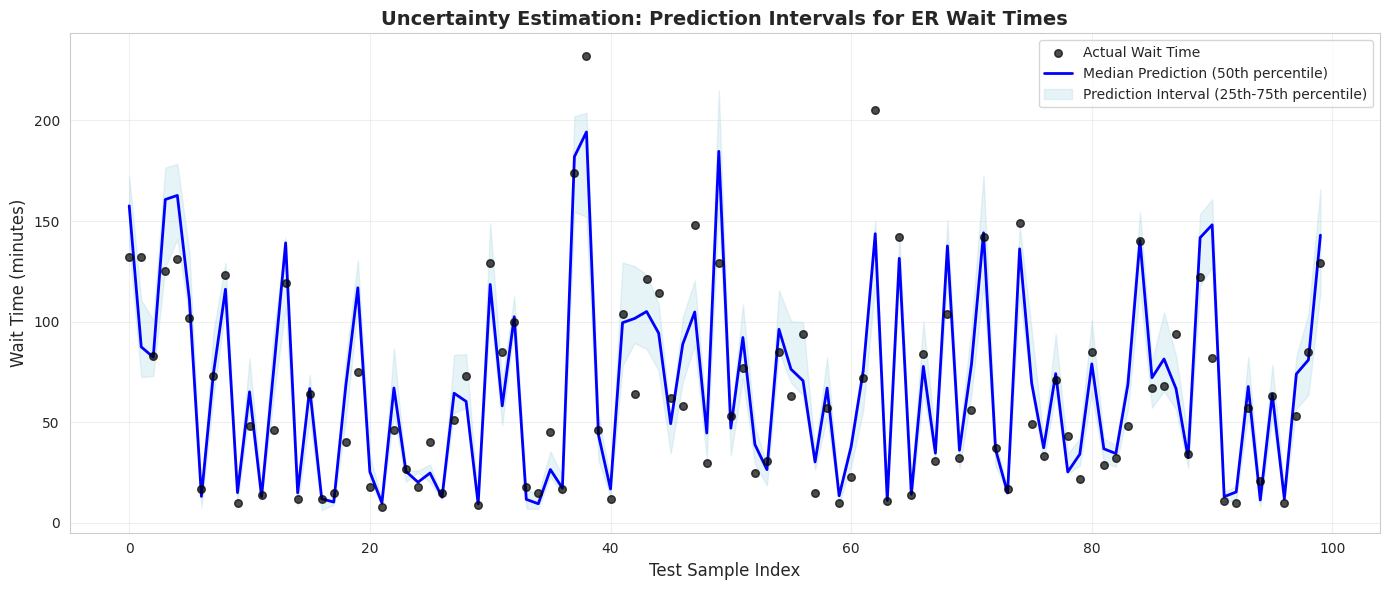


📊 Prediction Interval Coverage: 29.6%
   (Expected: ~50% for 25th-75th percentile interval)


In [25]:
# Visualize prediction intervals
fig, ax = plt.subplots(figsize=(14, 6))

sample_size = 100
indices = np.arange(sample_size)

# Plot actual values
ax.scatter(indices, y_reg_test.iloc[:sample_size], color='black', s=30, 
           label='Actual Wait Time', zorder=3, alpha=0.7)

# Plot median prediction
ax.plot(indices, pred_median[:sample_size], color='blue', linewidth=2, 
        label='Median Prediction (50th percentile)', zorder=2)

# Plot prediction interval
ax.fill_between(indices, pred_lower[:sample_size], pred_upper[:sample_size], 
                 alpha=0.3, color='lightblue', label='Prediction Interval (25th-75th percentile)')

ax.set_xlabel('Test Sample Index', fontsize=12)
ax.set_ylabel('Wait Time (minutes)', fontsize=12)
ax.set_title('Uncertainty Estimation: Prediction Intervals for ER Wait Times', 
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)

plt.tight_layout()
save_figure('09_uncertainty_prediction_intervals.png')
plt.show()

# Calculate coverage (% of actual values within prediction interval)
coverage = ((y_reg_test >= pred_lower) & (y_reg_test <= pred_upper)).mean()
print(f"\n📊 Prediction Interval Coverage: {coverage*100:.1f}%")
print(f"   (Expected: ~50% for 25th-75th percentile interval)")

## 💾 Model Deployment Preparation

Saving trained models and creating inference pipeline for cloud deployment.

### 💾 Save Trained Models

In [26]:
import os

# Create models directory
models_dir = 'trained_models'
os.makedirs(models_dir, exist_ok=True)

# Save best regression model (XGBoost)
xgb_regression_path = os.path.join(models_dir, 'xgboost_regressor.pkl')
joblib.dump(xgb_model, xgb_regression_path)
print(f"✅ Saved XGBoost Regressor: {xgb_regression_path}")

# Save best classification model (XGBoost)
xgb_classification_path = os.path.join(models_dir, 'xgboost_classifier.pkl')
joblib.dump(xgb_clf, xgb_classification_path)
print(f"✅ Saved XGBoost Classifier: {xgb_classification_path}")

# Save scaler (for Linear/Logistic Regression if needed)
scaler_path = os.path.join(models_dir, 'feature_scaler.pkl')
joblib.dump(scaler, scaler_path)
print(f"✅ Saved Feature Scaler: {scaler_path}")

# Save feature columns order (critical for inference)
feature_info = {
    'feature_columns': feature_cols,
    'model_version': '1.0',
    'training_date': datetime.now().strftime('%Y-%m-%d'),
    'metrics': {
        'regression': {
            'test_mae': float(xgb_test_mae),
            'test_rmse': float(xgb_test_rmse),
            'test_r2': float(xgb_test_r2)
        },
        'classification': {
            'test_accuracy': float(xgb_clf_test_acc),
            'test_f1': float(xgb_clf_test_f1),
            'test_auc': float(xgb_clf_test_auc)
        }
    }
}

feature_info_path = os.path.join(models_dir, 'model_metadata.json')
with open(feature_info_path, 'w') as f:
    json.dump(feature_info, f, indent=2)
print(f"✅ Saved Model Metadata: {feature_info_path}")

# Save quantile models
for q, model in quantile_models.items():
    quantile_path = os.path.join(models_dir, f'xgboost_quantile_{int(q*100)}.pkl')
    joblib.dump(model, quantile_path)
    print(f"✅ Saved Quantile Model ({int(q*100)}th): {quantile_path}")

print(f"\n🎉 All models saved successfully in '{models_dir}/' directory!")

✅ Saved XGBoost Regressor: trained_models/xgboost_regressor.pkl
✅ Saved XGBoost Classifier: trained_models/xgboost_classifier.pkl
✅ Saved Feature Scaler: trained_models/feature_scaler.pkl
✅ Saved Model Metadata: trained_models/model_metadata.json
✅ Saved Quantile Model (25th): trained_models/xgboost_quantile_25.pkl
✅ Saved Quantile Model (50th): trained_models/xgboost_quantile_50.pkl
✅ Saved Quantile Model (75th): trained_models/xgboost_quantile_75.pkl

🎉 All models saved successfully in 'trained_models/' directory!


### 🔌 Inference Pipeline for FastAPI

Creating a complete inference function compatible with cloud deployment.

In [27]:
def preprocess_input(data):
    """
    Preprocess raw input data for model inference
    
    Args:
        data (dict): Raw patient data
        
    Returns:
        pd.DataFrame: Preprocessed features ready for prediction
    """
    # Convert to DataFrame
    df_input = pd.DataFrame([data])
    
    # Convert arrival_time to datetime
    df_input['arrival_time'] = pd.to_datetime(df_input['arrival_time'])
    
    # Extract temporal features
    df_input['arrival_hour'] = df_input['arrival_time'].dt.hour
    df_input['arrival_day_of_week'] = df_input['arrival_time'].dt.dayofweek
    df_input['arrival_month'] = df_input['arrival_time'].dt.month
    df_input['arrival_day'] = df_input['arrival_time'].dt.day
    
    # Time of day categorization
    def categorize_time_of_day(hour):
        if 6 <= hour < 12:
            return 'morning'
        elif 12 <= hour < 18:
            return 'afternoon'
        elif 18 <= hour < 24:
            return 'evening'
        else:
            return 'night'
    
    df_input['time_of_day'] = df_input['arrival_hour'].apply(categorize_time_of_day)
    
    # Weekend flag
    df_input['is_weekend'] = (df_input['arrival_day_of_week'] >= 5).astype(int)
    
    # Rush hour indicator
    df_input['is_rush_hour'] = ((df_input['arrival_hour'].between(9, 11)) | 
                                 (df_input['arrival_hour'].between(18, 20))).astype(int)
    
    # Doctor-patient ratio
    df_input['doctor_patient_ratio'] = df_input['num_doctors_available'] / (df_input['queue_length'] + 1)
    
    # One-hot encode categorical variables
    df_input = pd.get_dummies(df_input, columns=['department', 'time_of_day'], 
                               prefix=['dept', 'tod'], drop_first=False)
    
    # Ensure all expected columns are present
    for col in feature_cols:
        if col not in df_input.columns:
            df_input[col] = 0
    
    # Select only required features in correct order
    df_input = df_input[feature_cols]
    
    return df_input


def predict_wait_time(data, return_interval=True):
    """
    Predict ER wait time with optional prediction interval
    
    Args:
        data (dict): Patient data
        return_interval (bool): Whether to return prediction interval
        
    Returns:
        dict: Prediction results
    """
    # Preprocess
    X = preprocess_input(data)
    
    # Point prediction
    wait_time_pred = xgb_model.predict(X)[0]
    
    # Classification prediction
    long_wait_prob = xgb_clf.predict_proba(X)[0, 1]
    is_long_wait = long_wait_prob > 0.5
    
    result = {
        'predicted_wait_time': float(wait_time_pred),
        'is_long_wait': bool(is_long_wait),
        'long_wait_probability': float(long_wait_prob),
        'risk_level': 'HIGH' if long_wait_prob > 0.7 else 'MEDIUM' if long_wait_prob > 0.3 else 'LOW'
    }
    
    # Add prediction interval if requested
    if return_interval:
        lower = quantile_models[0.25].predict(X)[0]
        median = quantile_models[0.5].predict(X)[0]
        upper = quantile_models[0.75].predict(X)[0]
        
        result['prediction_interval'] = {
            'lower_bound': float(lower),
            'median': float(median),
            'upper_bound': float(upper)
        }
    
    return result


# Test the inference pipeline
print("="*60)
print("🧪 TESTING INFERENCE PIPELINE")
print("="*60)

# Example input (FastAPI-compatible JSON format)
example_input = {
    'arrival_time': '2024-03-15 14:30:00',
    'triage_level': 3,
    'age': 45,
    'department': 'General',
    'num_doctors_available': 5,
    'queue_length': 12,
    'is_weekend': 0
}

print("\n📥 Input:")
print(json.dumps(example_input, indent=2))

# Get prediction
prediction = predict_wait_time(example_input, return_interval=True)

print("\n📤 Output:")
print(json.dumps(prediction, indent=2))

print("\n✅ Inference pipeline ready for deployment!")

🧪 TESTING INFERENCE PIPELINE

📥 Input:
{
  "arrival_time": "2024-03-15 14:30:00",
  "triage_level": 3,
  "age": 45,
  "department": "General",
  "num_doctors_available": 5,
  "queue_length": 12,
  "is_weekend": 0
}

📤 Output:
{
  "predicted_wait_time": 15.462260246276855,
  "is_long_wait": false,
  "long_wait_probability": 0.00011228452058276162,
  "risk_level": "LOW",
  "prediction_interval": {
    "lower_bound": 13.610797882080078,
    "median": 16.86355972290039,
    "upper_bound": 18.450407028198242
  }
}

✅ Inference pipeline ready for deployment!


### 📄 Example FastAPI Code Template

Below is a template for deploying the model as a REST API.

In [28]:
# Save FastAPI deployment template
fastapi_template = '''
"""
FastAPI Deployment Template for ER Wait Time Prediction
"""

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from datetime import datetime
import joblib
import pandas as pd
import numpy as np

app = FastAPI(title="ER Wait Time Predictor", version="1.0")

# Load models at startup
xgb_regressor = joblib.load("trained_models/xgboost_regressor.pkl")
xgb_classifier = joblib.load("trained_models/xgboost_classifier.pkl")
quantile_25 = joblib.load("trained_models/xgboost_quantile_25.pkl")
quantile_50 = joblib.load("trained_models/xgboost_quantile_50.pkl")
quantile_75 = joblib.load("trained_models/xgboost_quantile_75.pkl")

# Input schema
class PatientData(BaseModel):
    arrival_time: str
    triage_level: int
    age: int
    department: str
    num_doctors_available: int
    queue_length: int
    is_weekend: int = 0
    
    class Config:
        schema_extra = {
            "example": {
                "arrival_time": "2024-03-15 14:30:00",
                "triage_level": 3,
                "age": 45,
                "department": "General",
                "num_doctors_available": 5,
                "queue_length": 12,
                "is_weekend": 0
            }
        }

@app.get("/")
def root():
    return {"message": "ER Wait Time Prediction API", "version": "1.0"}

@app.get("/health")
def health_check():
    return {"status": "healthy"}

@app.post("/predict")
def predict(patient: PatientData):
    """Predict ER wait time for a patient"""
    try:
        # Convert to dict and use preprocessing function
        data = patient.dict()
        
        # [Include preprocess_input function here]
        # [Include predict_wait_time function here]
        
        prediction = predict_wait_time(data, return_interval=True)
        return {
            "status": "success",
            "prediction": prediction
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

# Run with: uvicorn main:app --reload
'''

# Save the template
api_template_path = os.path.join(models_dir, 'fastapi_template.py')
with open(api_template_path, 'w') as f:
    f.write(fastapi_template)

print(f"✅ FastAPI template saved: {api_template_path}")
print("\n📌 To deploy:")
print("   1. Copy trained_models/ directory to your server")
print("   2. Install: pip install fastapi uvicorn")
print("   3. Run: uvicorn fastapi_template:app --reload")
print("   4. Access API docs: http://localhost:8000/docs")

✅ FastAPI template saved: trained_models/fastapi_template.py

📌 To deploy:
   1. Copy trained_models/ directory to your server
   2. Install: pip install fastapi uvicorn
   3. Run: uvicorn fastapi_template:app --reload
   4. Access API docs: http://localhost:8000/docs


## 📋 Final Summary & Conclusions

In [29]:
print("="*80)
print("🏆 FINAL MODEL PERFORMANCE SUMMARY")
print("="*80)

print("\n📊 REGRESSION TASK: Wait Time Prediction")
print("-"*60)
print(regression_results.to_string(index=False))
print(f"\n🥇 Best Model: XGBoost Regressor")
print(f"   - Test MAE:  {xgb_test_mae:.2f} minutes")
print(f"   - Test RMSE: {xgb_test_rmse:.2f} minutes")
print(f"   - Test R²:   {xgb_test_r2:.4f}")

print("\n" + "="*60)
print("\n🎯 CLASSIFICATION TASK: Long-Wait Detection (>60 min)")
print("-"*60)
print(classification_results.to_string(index=False))
print(f"\n🥇 Best Model: XGBoost Classifier")
print(f"   - Test Accuracy:  {xgb_clf_test_acc:.4f}")
print(f"   - Test F1-Score:  {xgb_clf_test_f1:.4f}")
print(f"   - Test ROC-AUC:   {xgb_clf_test_auc:.4f}")

print("\n" + "="*60)
print("🔧 KEY FEATURES (Top 5 by Importance)")
print("-"*60)
for idx, row in xgb_importance.head(5).iterrows():
    print(f"   {row['Feature']}")

print("\n" + "="*60)
print("📁 SAVED ARTIFACTS")
print("-"*60)
for f in os.listdir(models_dir):
    print(f"   ✓ {models_dir}/{f}")

🏆 FINAL MODEL PERFORMANCE SUMMARY

📊 REGRESSION TASK: Wait Time Prediction
------------------------------------------------------------
            Model  Train MAE  Test MAE  Train RMSE  Test RMSE  Train R²  Test R²
Linear Regression  24.332926 28.270612   33.097065  38.914289  0.758990 0.658235
    Random Forest  12.048353 22.647789   18.016779  35.032165  0.928582 0.723023
          XGBoost   8.259670 23.279178   11.788576  35.569929  0.969424 0.714454

🥇 Best Model: XGBoost Regressor
   - Test MAE:  23.28 minutes
   - Test RMSE: 35.57 minutes
   - Test R²:   0.7145


🎯 CLASSIFICATION TASK: Long-Wait Detection (>60 min)
------------------------------------------------------------
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression     0.872   0.934426 0.799599  0.861771 0.962880
            XGBoost     0.883   0.934091 0.823647  0.875399 0.968004

🥇 Best Model: XGBoost Classifier
   - Test Accuracy:  0.8830
   - Test F1-Score:  0.8754
   - Test R

### 🚀 Deployment Checklist

| Step | Status | Notes |
|------|--------|-------|
| EDA & Data Understanding | ✅ Complete | Analyzed distributions, correlations |
| Feature Engineering | ✅ Complete | Temporal, operational features |
| Regression Models | ✅ Complete | LR, RF, XGBoost |
| Classification Models | ✅ Complete | LogReg, XGBoost |
| Model Comparison | ✅ Complete | Tables & visualizations |
| Uncertainty Estimation | ✅ Complete | Quantile regression |
| Model Saving | ✅ Complete | joblib/pickle format |
| Inference Pipeline | ✅ Complete | FastAPI-compatible |
| Documentation | ✅ Complete | Markdown explanations |

**Next Steps for Cloud Deployment:**
1. Upload notebook to Kaggle for final training
2. Copy `trained_models/` to cloud storage (S3, GCS)
3. Deploy FastAPI service on cloud platform (AWS Lambda, Cloud Run, etc.)
4. Set up model monitoring and logging
5. Configure CI/CD for model retraining

### ⚠️ Limitations & Bias Risks

**Data Limitations:**
- Model trained on synthetic/limited data - real hospital data may behave differently
- Time-based splitting may miss seasonal patterns (e.g., flu season)
- Feature engineering assumes consistent data collection practices

**Potential Biases:**
- Triage level assignments may vary by staff experience
- Queue length may not capture patient severity distribution
- Weekend/rush hour effects may differ by hospital location

**Recommendations for Production:**
1. Validate with real hospital data before deployment
2. Monitor for data drift in production
3. Regularly retrain models with fresh data
4. Implement A/B testing before full rollout
5. Have human oversight for critical decisions

In [30]:
import os
import zipfile

# Define source and output paths
source_dir = '/kaggle/working/'
output_zip = '/kaggle/working/final_version.zip'

# Define allowed extensions
allowed_ext = {'.pth', '.png', '.csv', '.db','.json','.pkl','.py'}

# Create the zip file
with zipfile.ZipFile(output_zip, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(source_dir):
        # Skip checkpoints and hidden dirs
        dirs[:] = [d for d in dirs if d != '.ipynb_checkpoints']
        for file in files:
            ext = os.path.splitext(file)[1].lower()
            if ext in allowed_ext:
                file_path = os.path.join(root, file)
                arcname = os.path.relpath(file_path, source_dir)
                zipf.write(file_path, arcname)
                print(f"📦 Added: {arcname}")

print("\n✅ Done! Created 'selected_files.zip' with .pth, .png, .csv, and .db files only.")

📦 Added: trained_models/xgboost_quantile_25.pkl
📦 Added: trained_models/model_metadata.json
📦 Added: trained_models/xgboost_classifier.pkl
📦 Added: trained_models/xgboost_quantile_75.pkl
📦 Added: trained_models/xgboost_regressor.pkl
📦 Added: trained_models/feature_scaler.pkl
📦 Added: trained_models/xgboost_quantile_50.pkl
📦 Added: trained_models/fastapi_template.py
📦 Added: figures/02_categorical_features_analysis.png
📦 Added: figures/04_regression_models_comparison.png
📦 Added: figures/03_correlation_heatmap.png
📦 Added: figures/05_feature_importance.png
📦 Added: figures/06_error_analysis.png
📦 Added: figures/07_classification_models_comparison.png
📦 Added: figures/09_uncertainty_prediction_intervals.png
📦 Added: figures/01_wait_time_distribution.png
📦 Added: figures/08_confusion_matrix_roc_curve.png

✅ Done! Created 'selected_files.zip' with .pth, .png, .csv, and .db files only.


## 📚 Appendix: Sample JSON Input/Output for API

### Example Request
```json
{
  "arrival_time": "2024-03-15 14:30:00",
  "triage_level": 3,
  "age": 45,
  "department": "General",
  "num_doctors_available": 5,
  "queue_length": 12,
  "is_weekend": 0
}
```

### Example Response
```json
{
  "status": "success",
  "prediction": {
    "predicted_wait_time": 65.3,
    "is_long_wait": true,
    "long_wait_probability": 0.72,
    "risk_level": "HIGH",
    "prediction_interval": {
      "lower_bound": 45.2,
      "median": 62.8,
      "upper_bound": 85.1
    }
  }
}
```

---
*Notebook created for AI-Powered Cloud Scheduler for Hospital Emergency Rooms*  
*Training environment: Kaggle (CPU-only)*  
*Target deployment: FastAPI on cloud infrastructure*